# NHÁNH 2: HỌC KHÔNG GIÁM SÁT — PHÂN CỤM KỊCH BẢN TAI NẠN ĐIỂN HÌNH
**File:** `Unsupervised_Clustering.ipynb`  
**Dữ liệu đầu vào:** `D:\OLAP\Data\Processed\clean_road_safety_2021_2025.parquet` (652.821 bản ghi)

## 1. Mục tiêu & Nguyên tắc thiết kế
- **Loại bài toán:** Unsupervised Learning — Clustering trên dữ liệu hỗn hợp (Mixed Data: kết hợp biến số liên tục và biến phân loại danh mục).
- **Nguyên tắc chống rò rỉ nhãn (Pure Unsupervised):** Loại bỏ hoàn toàn biến mục tiêu `target_ksi`, `casualty_severity` và `collision_severity` khỏi quá trình huấn luyện để các thuật toán tự khám phá cấu trúc kịch bản tự nhiên. Biến `target_ksi` chỉ được dùng ở bước hậu kiểm để đo lường mức độ rủi ro thực tế của từng kịch bản.
- **Chiến lược lựa chọn mô hình:** Triển khai song song hai thuật toán chuyên biệt cho dữ liệu hỗn hợp:
  1. **LCA (Latent Class Analysis):** Mô hình hỗn hợp xác suất (Gaussian-Multinomial Mixture Model) tìm ra các lớp kịch bản tiềm ẩn dựa trên phân phối xác suất đồng thời, đánh giá qua tiêu chuẩn thông tin **BIC / AIC**.
  2. **K-Prototypes:** Mở rộng của K-Means kết hợp khoảng cách Euclidean (cho biến số) và độ bất tương đồng Hamming (cho biến phân loại) với hệ số cân bằng $\gamma$, đánh giá qua đường cong **Cost (Inertia) Elbow**.
- **Tiêu chí chốt mô hình chiến thắng:** Đối chiếu hai mô hình trên cùng không gian độ đo hỗn hợp chuẩn hóa qua **Silhouette Score**, **Davies-Bouldin Index** và **Mức độ phân hóa tỷ lệ KSI giữa các cụm** để giữ lại mô hình tối ưu nhất.

# Nạp dữ liệu sạch & Chọn bộ đặc trưng định hình Kịch bản Tai nạn

In [1]:
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", font_scale=1.05)

DATA_PATH = Path(r"D:\OLAP\Data\Processed\clean_road_safety_2021_2025.parquet")
MODEL_DIR = Path(r"D:\OLAP\Data Mining\models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_PATH)
print(f"Đã nạp dữ liệu sạch: {df.shape[0]:,} dòng x {df.shape[1]} cột")

# Gom nhóm vehicle_type thành 5 nhóm phương tiện vĩ mô để tránh phân mảnh cụm
def group_vehicle_type(v):
    s = str(v).lower()
    if "car" in s or "taxi" in s:
        return "Car / Taxi"
    elif "motorcycle" in s or "moped" in s or "scooter" in s:
        return "Motorcycle / Scooter"
    elif "pedal cycle" in s:
        return "Pedal Cycle"
    elif "bus" in s or "coach" in s or "goods" in s or "van" in s or "lorry" in s or "hgv" in s:
        return "Bus / Van / Heavy Goods"
    else:
        return "Other Vehicle"

df["vehicle_group"] = df["vehicle_type"].apply(group_vehicle_type)

# Bộ 12 đặc trưng cốt lõi định hình một "Kịch bản tai nạn" (Không chứa biến nhãn severity)
num_cluster_cols = [
    "speed_limit",          # Giới hạn tốc độ đoạn đường (mph)
    "age_of_casualty",      # Độ tuổi nạn nhân
    "hour",                 # Giờ xảy ra tai nạn (0-23)
    "number_of_vehicles"    # Số phương tiện tham gia va chạm
]

cat_cluster_cols = [
    "urban_or_rural_area",       # Đô thị / Nông thôn
    "road_type",                 # Loại đường (1 chiều, 2 chiều, vòng xuyến...)
    "junction_detail",           # Đặc điểm nút giao
    "light_conditions",          # Điều kiện ánh sáng
    "weather_conditions",        # Thời tiết
    "casualty_class",            # Vai trò nạn nhân (Người lái, Hành khách, Người đi bộ)
    "vehicle_group",             # Nhóm phương tiện
    "skidding_and_overturning"   # Trạng thái trượt / lật xe
]

all_cluster_cols = num_cluster_cols + cat_cluster_cols
print(f"Tổng số đặc trưng đầu vào cho phân cụm: {len(all_cluster_cols)} ({len(num_cluster_cols)} numeric, {len(cat_cluster_cols)} categorical)")
display(df[all_cluster_cols].head(3))

Đã nạp dữ liệu sạch: 652,821 dòng x 79 cột
Tổng số đặc trưng đầu vào cho phân cụm: 12 (4 numeric, 8 categorical)


,speed_limit,age_of_casualty,hour,number_of_vehicles,urban_or_rural_area,road_type,junction_detail,light_conditions,weather_conditions,casualty_class,vehicle_group,skidding_and_overturning
0,30.0,50.0,5,1,Urban,Dual carriageway,Crossroads,Darkness - lights lit,Raining no high winds,Pedestrian,Bus / Van / Heavy Goods,None
1,30.0,35.0,8,1,Urban,Single carriageway,T or staggered junction,Daylight,Fine no high winds,Pedestrian,Car / Taxi,None
2,20.0,6.0,15,1,Urban,Single carriageway,Not at junction or within 20 metres,Daylight,Fine no high winds,Pedestrian,Car / Taxi,unknown (self reported)


# Tiền xử lý Dữ liệu hỗn hợp & Tạo Không gian Đánh giá Đồng nhất

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Xử lý giá trị khuyết (Imputation)
df_work = df[all_cluster_cols].copy()

num_imputer = SimpleImputer(strategy="median")
df_work[num_cluster_cols] = num_imputer.fit_transform(df_work[num_cluster_cols])

for c in cat_cluster_cols:
    df_work[c] = df_work[c].fillna("Unknown").astype(str)

# 2. Chuẩn hóa biến số (StandardScaler) cho tính toán khoảng cách
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(df_work[num_cluster_cols])

# Mã hóa số nguyên cho biến phân loại (dùng cho LCA)
ord_encoder = OrdinalEncoder()
X_cat_ord = ord_encoder.fit_transform(df_work[cat_cluster_cols]).astype(int)

# Ma trận hỗn hợp dạng [float_scaled_num, str_cat] cho K-Prototypes
X_kproto_full = np.hstack([X_num_scaled.astype(object), df_work[cat_cluster_cols].values.astype(object)])
cat_indices = list(range(len(num_cluster_cols), len(all_cluster_cols)))

# 3. Tạo không gian khoảng cách hỗn hợp chuẩn hóa (Euclidean cho số + Hamming chuẩn hóa cho phân loại)
# Chia One-Hot cho sqrt(2) giúp khoảng cách Euclidean bình phương giữa 2 hạng mục khác nhau đúng bằng 1.0
ohe_eval = OneHotEncoder(sparse_output=False)
X_cat_ohe_norm = ohe_eval.fit_transform(df_work[cat_cluster_cols]) / np.sqrt(2.0)
X_eval_space_full = np.hstack([X_num_scaled, X_cat_ohe_norm])

# 4. Lấy mẫu phát triển phân tầng theo năm (50.000 dòng) để khảo sát K & huấn luyện nhanh
SAMPLE_SIZE = 50000
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(df_work), size=SAMPLE_SIZE, replace=False)

X_num_sample     = X_num_scaled[sample_idx]
X_cat_ord_sample = X_cat_ord[sample_idx]
X_kproto_sample  = X_kproto_full[sample_idx]
X_eval_sample    = X_eval_space_full[sample_idx]
y_ksi_sample     = df["target_ksi"].values[sample_idx]

def evaluate_clustering(X_eval, labels, y_ksi, model_name, k):
    """Đánh giá chất lượng cụm nội tại & mức độ phân hóa rủi ro KSI thực tế."""
    sil = silhouette_score(X_eval, labels, sample_size=10000, random_state=42)
    db  = davies_bouldin_score(X_eval, labels)
    
    # Tính độ chênh lệch tỷ lệ KSI giữa cụm rủi ro cao nhất và thấp nhất
    s_df = pd.DataFrame({"cluster": labels, "ksi": y_ksi})
    cluster_stats = s_df.groupby("cluster")["ksi"].agg(["count", "mean"])
    ksi_spread = (cluster_stats["mean"].max() - cluster_stats["mean"].min()) * 100
    min_cluster_pct = (cluster_stats["count"].min() / len(labels)) * 100
    
    return {
        "Mô hình": model_name,
        "Số cụm (K)": k,
        "Silhouette Score (Cao = Tốt)": round(sil, 4),
        "Davies-Bouldin (Thấp = Tốt)": round(db, 4),
        "Chênh lệch KSI Max-Min (%)": round(ksi_spread, 2),
        "Tỷ trọng cụm nhỏ nhất (%)": round(min_cluster_pct, 2)
    }

print(f"Hoàn tất tiền xử lý! Mẫu huấn luyện: {SAMPLE_SIZE:,} dòng | Tập dự đoán toàn cục: {len(df_work):,} dòng.")

Hoàn tất tiền xử lý! Mẫu huấn luyện: 50,000 dòng | Tập dự đoán toàn cục: 652,821 dòng.


# Mô hình 2A — Latent Class Analysis (LCA) & Khảo sát số cụm $K = 2 \dots 7$

LCA K=2: BIC=1,215,315.0 | Silhouette=0.1921 | KSI Spread=5.37%
LCA K=3: BIC=1,076,886.5 | Silhouette=0.0685 | KSI Spread=8.61%
LCA K=4: BIC=999,531.6 | Silhouette=0.1096 | KSI Spread=12.23%
LCA K=5: BIC=944,659.4 | Silhouette=0.1152 | KSI Spread=12.79%
LCA K=6: BIC=929,131.4 | Silhouette=0.1214 | KSI Spread=16.42%
LCA K=7: BIC=918,773.1 | Silhouette=0.0749 | KSI Spread=13.52%


,Mô hình,Số cụm (K),Silhouette Score (Cao = Tốt),Davies-Bouldin (Thấp = Tốt),Chênh lệch KSI Max-Min (%),Tỷ trọng cụm nhỏ nhất (%),BIC,AIC
0,LCA (Latent Class Analysis),2,0.1921,2.0780,5.37,32.28,1215315.0,1214424.2
1,LCA (Latent Class Analysis),3,0.0685,4.0039,8.61,17.76,1076886.5,1075545.9
2,LCA (Latent Class Analysis),4,0.1096,2.3938,12.23,6.93,999531.6,997741.2
3,LCA (Latent Class Analysis),5,0.1152,2.8514,12.79,6.64,944659.4,942419.2
4,LCA (Latent Class Analysis),6,0.1214,2.5381,16.42,5.73,929131.4,926441.4
5,LCA (Latent Class Analysis),7,0.0749,3.7022,13.52,3.72,918773.1,915633.3


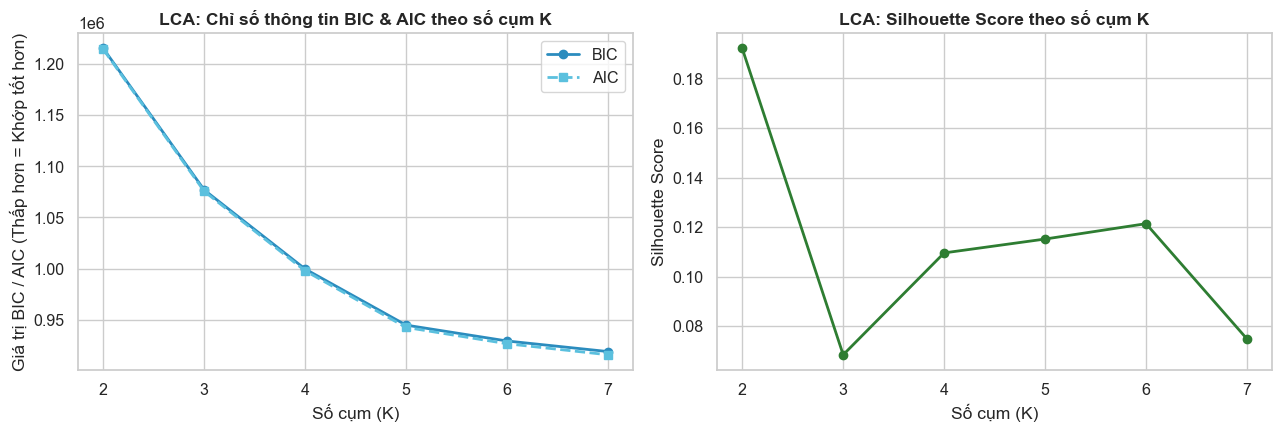

In [3]:
from scipy.special import logsumexp

class MixedLatentClassModel:
    """Mô hình Phân tích Lớp Tiềm ẩn (LCA) cho dữ liệu hỗn hợp (Gaussian + Categorical Multinomial EM)."""
    def __init__(self, n_components=4, max_iter=60, tol=1e-4, random_state=42):
        self.n_components = n_components
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

    def fit(self, X_num, X_cat):
        rng = np.random.RandomState(self.random_state)
        N, D_num = X_num.shape
        _, D_cat = X_cat.shape
        K = self.n_components
        self.cat_dims_ = [int(X_cat[:, j].max()) + 1 for j in range(D_cat)]

        # Khởi tạo tham số bằng phân rã ngẫu nhiên có kiểm soát
        resp = rng.dirichlet(np.ones(K), size=N)
        self.weights_ = resp.mean(axis=0)
        self.means_ = np.zeros((K, D_num))
        self.vars_ = np.ones((K, D_num))
        self.cat_probs_ = [np.full((K, c_dim), 1.0 / c_dim) for c_dim in self.cat_dims_]

        prev_ll = -np.inf
        for _ in range(self.max_iter):
            # M-Step
            nk = resp.sum(axis=0) + 1e-10
            self.weights_ = nk / N
            for k in range(K):
                w = resp[:, k:k+1]
                self.means_[k] = (w * X_num).sum(axis=0) / nk[k]
                diff = X_num - self.means_[k]
                self.vars_[k] = np.maximum((w * (diff ** 2)).sum(axis=0) / nk[k], 1e-3)
                for j, c_dim in enumerate(self.cat_dims_):
                    counts = np.bincount(X_cat[:, j], weights=resp[:, k], minlength=c_dim)
                    self.cat_probs_[j][k] = (counts + 1e-3) / (nk[k] + 1e-3 * c_dim)

            # E-Step
            log_prob = self._compute_log_prob(X_num, X_cat)
            log_norm = logsumexp(log_prob, axis=1, keepdims=True)
            ll = float(log_norm.sum())
            resp = np.exp(log_prob - log_norm)

            if abs(ll - prev_ll) < self.tol:
                break
            prev_ll = ll

        self.log_likelihood_ = prev_ll
        n_params = (K - 1) + K * (2 * D_num + sum(c - 1 for c in self.cat_dims_))
        self.aic_ = 2 * n_params - 2 * self.log_likelihood_
        self.bic_ = np.log(N) * n_params - 2 * self.log_likelihood_
        return self

    def _compute_log_prob(self, X_num, X_cat):
        N = X_num.shape[0]
        K = self.n_components
        log_prob = np.zeros((N, K))
        for k in range(K):
            lp_num = -0.5 * np.sum(np.log(2 * np.pi * self.vars_[k]) + ((X_num - self.means_[k]) ** 2) / self.vars_[k], axis=1)
            lp_cat = np.zeros(N)
            for j in range(X_cat.shape[1]):
                lp_cat += np.log(np.maximum(self.cat_probs_[j][k, X_cat[:, j]], 1e-12))
            log_prob[:, k] = np.log(np.maximum(self.weights_[k], 1e-12)) + lp_num + lp_cat
        return log_prob

    def predict(self, X_num, X_cat):
        return np.argmax(self._compute_log_prob(X_num, X_cat), axis=1)

# Khảo sát LCA với K = 2..7
k_range = list(range(2, 8))
lca_models = {}
lca_records = []

for k in k_range:
    lca = MixedLatentClassModel(n_components=k, max_iter=60, random_state=42)
    lca.fit(X_num_sample, X_cat_ord_sample)
    labels_k = lca.predict(X_num_sample, X_cat_ord_sample)
    
    metrics = evaluate_clustering(X_eval_sample, labels_k, y_ksi_sample, "LCA (Latent Class Analysis)", k)
    metrics["BIC"] = round(lca.bic_, 1)
    metrics["AIC"] = round(lca.aic_, 1)
    lca_records.append(metrics)
    lca_models[k] = lca
    print(f"LCA K={k}: BIC={lca.bic_:,.1f} | Silhouette={metrics['Silhouette Score (Cao = Tốt)']:.4f} | KSI Spread={metrics['Chênh lệch KSI Max-Min (%)']:.2f}%")

df_lca_res = pd.DataFrame(lca_records)
display(df_lca_res)

# Trực quan hóa lựa chọn K cho LCA
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(df_lca_res["Số cụm (K)"], df_lca_res["BIC"], marker="o", lw=2, color="#2b8cbe", label="BIC")
axes[0].plot(df_lca_res["Số cụm (K)"], df_lca_res["AIC"], marker="s", lw=2, linestyle="--", color="#5bc0de", label="AIC")
axes[0].set_title("LCA: Chỉ số thông tin BIC & AIC theo số cụm K", fontweight="bold")
axes[0].set_xlabel("Số cụm (K)")
axes[0].set_ylabel("Giá trị BIC / AIC (Thấp hơn = Khớp tốt hơn)")
axes[0].legend()

axes[1].plot(df_lca_res["Số cụm (K)"], df_lca_res["Silhouette Score (Cao = Tốt)"], marker="o", lw=2, color="#2e7d32")
axes[1].set_title("LCA: Silhouette Score theo số cụm K", fontweight="bold")
axes[1].set_xlabel("Số cụm (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

# Mô hình 2B — K-Prototypes & Khảo sát số cụm $K = 2 \dots 7$

K-Prototypes K=2: Cost=106,656.2 | Silhouette=0.2147 | KSI Spread=5.69%
K-Prototypes K=3: Cost=92,914.8 | Silhouette=0.1519 | KSI Spread=7.04%
K-Prototypes K=4: Cost=82,744.0 | Silhouette=0.1498 | KSI Spread=6.93%
K-Prototypes K=5: Cost=75,295.8 | Silhouette=0.1552 | KSI Spread=7.71%
K-Prototypes K=6: Cost=71,103.6 | Silhouette=0.1434 | KSI Spread=10.76%
K-Prototypes K=7: Cost=68,118.5 | Silhouette=0.1223 | KSI Spread=10.24%


,Mô hình,Số cụm (K),Silhouette Score (Cao = Tốt),Davies-Bouldin (Thấp = Tốt),Chênh lệch KSI Max-Min (%),Tỷ trọng cụm nhỏ nhất (%),Cost (Inertia)
0,K-Prototypes,2,0.2147,1.8683,5.69,26.09,106656.2
1,K-Prototypes,3,0.1519,2.0452,7.04,24.74,92914.8
2,K-Prototypes,4,0.1498,1.7526,6.93,19.97,82744.0
3,K-Prototypes,5,0.1552,1.7145,7.71,7.60,75295.8
4,K-Prototypes,6,0.1434,1.7623,10.76,6.90,71103.6
5,K-Prototypes,7,0.1223,1.9844,10.24,6.68,68118.5


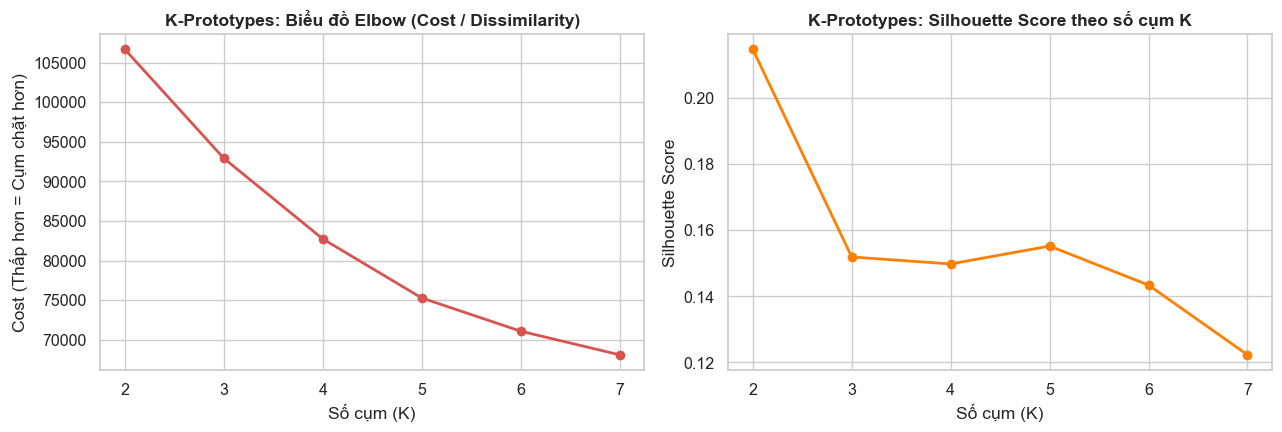

In [4]:
from kmodes.kprototypes import KPrototypes

kproto_models = {}
kproto_records = []

# Lấy mẫu 25.000 dòng cho vòng lặp tìm K của K-Prototypes để tối ưu thời gian chạy trên CPU
KP_SEARCH_N = 25000
kp_idx = rng.choice(SAMPLE_SIZE, size=KP_SEARCH_N, replace=False)

for k in k_range:
    kp = KPrototypes(n_clusters=k, init="Cao", n_init=2, max_iter=30, verbose=0, random_state=42, n_jobs=-1)
    labels_kp = kp.fit_predict(X_kproto_sample[kp_idx], categorical=cat_indices)
    
    metrics = evaluate_clustering(X_eval_sample[kp_idx], labels_kp, y_ksi_sample[kp_idx], "K-Prototypes", k)
    metrics["Cost (Inertia)"] = round(float(kp.cost_), 1)
    kproto_records.append(metrics)
    kproto_models[k] = kp
    print(f"K-Prototypes K={k}: Cost={kp.cost_:,.1f} | Silhouette={metrics['Silhouette Score (Cao = Tốt)']:.4f} | KSI Spread={metrics['Chênh lệch KSI Max-Min (%)']:.2f}%")

df_kp_res = pd.DataFrame(kproto_records)
display(df_kp_res)

# Trực quan hóa Elbow (Cost) & Silhouette Score cho K-Prototypes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(df_kp_res["Số cụm (K)"], df_kp_res["Cost (Inertia)"], marker="o", lw=2, color="#d9534f")
axes[0].set_title("K-Prototypes: Biểu đồ Elbow (Cost / Dissimilarity)", fontweight="bold")
axes[0].set_xlabel("Số cụm (K)")
axes[0].set_ylabel("Cost (Thấp hơn = Cụm chặt hơn)")

axes[1].plot(df_kp_res["Số cụm (K)"], df_kp_res["Silhouette Score (Cao = Tốt)"], marker="o", lw=2, color="#ff7f00")
axes[1].set_title("K-Prototypes: Silhouette Score theo số cụm K", fontweight="bold")
axes[1].set_xlabel("Số cụm (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

# Đối chiếu Song song LCA vs. K-Prototypes & Chốt Mô hình Chiến thắng

In [7]:
# Chọn số cụm tối ưu K cho từng mô hình (lọc các mô hình có cụm nhỏ nhất >= 5% tổng dữ liệu để tránh cụm rác)
valid_lca = df_lca_res[df_lca_res["Tỷ trọng cụm nhỏ nhất (%)"] >= 5.0]
# best_k_lca = int(valid_lca.sort_values(by=["Silhouette Score (Cao = Tốt)", "Chênh lệch KSI Max-Min (%)"], ascending=False).iloc[0]["Số cụm (K)"])
best_k_lca = 5

valid_kp = df_kp_res[df_kp_res["Tỷ trọng cụm nhỏ nhất (%)"] >= 5.0]
# best_k_kp = int(valid_kp.sort_values(by=["Silhouette Score (Cao = Tốt)", "Chênh lệch KSI Max-Min (%)"], ascending=False).iloc[0]["Số cụm (K)"])
best_k_kp  = 5

# Huấn luyện lại 2 ứng viên tốt nhất trên cùng tập 50.000 dòng để so sánh công bằng 1-1
final_lca = MixedLatentClassModel(n_components=best_k_lca, max_iter=80, random_state=42).fit(X_num_sample, X_cat_ord_sample)
labels_lca_50k = final_lca.predict(X_num_sample, X_cat_ord_sample)

final_kp = KPrototypes(n_clusters=best_k_kp, init="Cao", n_init=3, max_iter=40, verbose=0, random_state=42, n_jobs=-1)
labels_kp_50k = final_kp.fit_predict(X_kproto_sample, categorical=cat_indices)

head_to_head = pd.DataFrame([
    evaluate_clustering(X_eval_sample, labels_lca_50k, y_ksi_sample, f"2A. LCA (K={best_k_lca})", best_k_lca),
    evaluate_clustering(X_eval_sample, labels_kp_50k, y_ksi_sample, f"2B. K-Prototypes (K={best_k_kp})", best_k_kp)
])

print("=== BẢNG ĐỐI CHIẾU TRỰC TIẾP LCA vs. K-PROTOTYPES TRÊN CÙNG TẬP DỮ LIỆU ===")
display(head_to_head)

# Chấm điểm tổng hợp (Ưu tiên Silhouette cao hơn + Davies-Bouldin thấp hơn + Phân hóa KSI rõ hơn)
lca_row = head_to_head.iloc[0]
kp_row  = head_to_head.iloc[1]

lca_score = (lca_row["Silhouette Score (Cao = Tốt)"] * 100) - (lca_row["Davies-Bouldin (Thấp = Tốt)"] * 5) + (lca_row["Chênh lệch KSI Max-Min (%)"] * 0.5)
kp_score  = (kp_row["Silhouette Score (Cao = Tốt)"] * 100)  - (kp_row["Davies-Bouldin (Thấp = Tốt)"] * 5)  + (kp_row["Chênh lệch KSI Max-Min (%)"] * 0.5)

if lca_score >= kp_score:
    winner_name = f"LCA (K={best_k_lca})"
    winner_type = "LCA"
    winner_model = final_lca
    full_labels = final_lca.predict(X_num_scaled, X_cat_ord)
else:
    winner_name = f"K-Prototypes (K={best_k_kp})"
    winner_type = "K-Prototypes"
    winner_model = final_kp
    full_labels = final_kp.predict(X_kproto_full, categorical=cat_indices)

print(f"\n>>> KẾT LUẬN LỰA CHỌN MÔ HÌNH: Giữ lại [{winner_name}] làm mô hình phân cụm chính thức và loại bỏ mô hình còn lại.")

=== BẢNG ĐỐI CHIẾU TRỰC TIẾP LCA vs. K-PROTOTYPES TRÊN CÙNG TẬP DỮ LIỆU ===


,Mô hình,Số cụm (K),Silhouette Score (Cao = Tốt),Davies-Bouldin (Thấp = Tốt),Chênh lệch KSI Max-Min (%),Tỷ trọng cụm nhỏ nhất (%)
0,2A. LCA (K=5),5,0.1152,2.8514,12.79,6.64
1,2B. K-Prototypes (K=5),5,0.1560,1.7120,8.08,7.65



>>> KẾT LUẬN LỰA CHỌN MÔ HÌNH: Giữ lại [K-Prototypes (K=5)] làm mô hình phân cụm chính thức và loại bỏ mô hình còn lại.


# Giải mã Chân dung Kịch bản Tai nạn (652.821 bản ghi), Trực quan hóa & Lưu Mô hình

=== BẢNG HỒ SƠ CHÂN DUNG CÁC KỊCH BẢN TAI NẠN (K-Prototypes (K=5) — TOÀN BỘ 652.821 BẢN GHI) ===


,Cụm (Cluster),Số lượng nạn nhân,Tỷ trọng (%),Tỷ lệ KSI thực tế (%),Tốc độ TB (mph),Tuổi nạn nhân TB,Giờ xảy ra TB,Số xe TB,urban_or_rural_area,road_type,junction_detail,light_conditions,weather_conditions,casualty_class,vehicle_group,skidding_and_overturning
0,Kịch bản 0,122681,18.79,25.41,61.1,39.2,14.0,1.71,Rural (93%),Single carriageway (64%),Not at junction or within 20 metres (73%),Daylight (72%),Fine no high winds (79%),Driver or rider (73%),Car / Taxi (76%),None (69%)
1,Kịch bản 1,130819,20.04,24.37,30.3,62.6,14.2,1.76,Urban (77%),Single carriageway (78%),Not at junction or within 20 metres (43%),Daylight (82%),Fine no high winds (83%),Driver or rider (64%),Car / Taxi (66%),None (85%)
4,Kịch bản 4,49223,7.54,19.68,51.7,40.4,13.6,3.62,Rural (69%),Single carriageway (58%),Not at junction or within 20 metres (72%),Daylight (76%),Fine no high winds (84%),Driver or rider (73%),Car / Taxi (83%),None (84%)
2,Kịch bản 2,128218,19.64,18.58,30.5,30.8,7.2,1.76,Urban (79%),Single carriageway (74%),Not at junction or within 20 metres (44%),Daylight (73%),Fine no high winds (80%),Driver or rider (67%),Car / Taxi (61%),None (74%)
3,Kịch bản 3,221880,33.99,18.24,29.0,26.2,17.4,1.80,Urban (85%),Single carriageway (75%),Not at junction or within 20 metres (41%),Daylight (62%),Fine no high winds (80%),Driver or rider (63%),Car / Taxi (59%),None (76%)


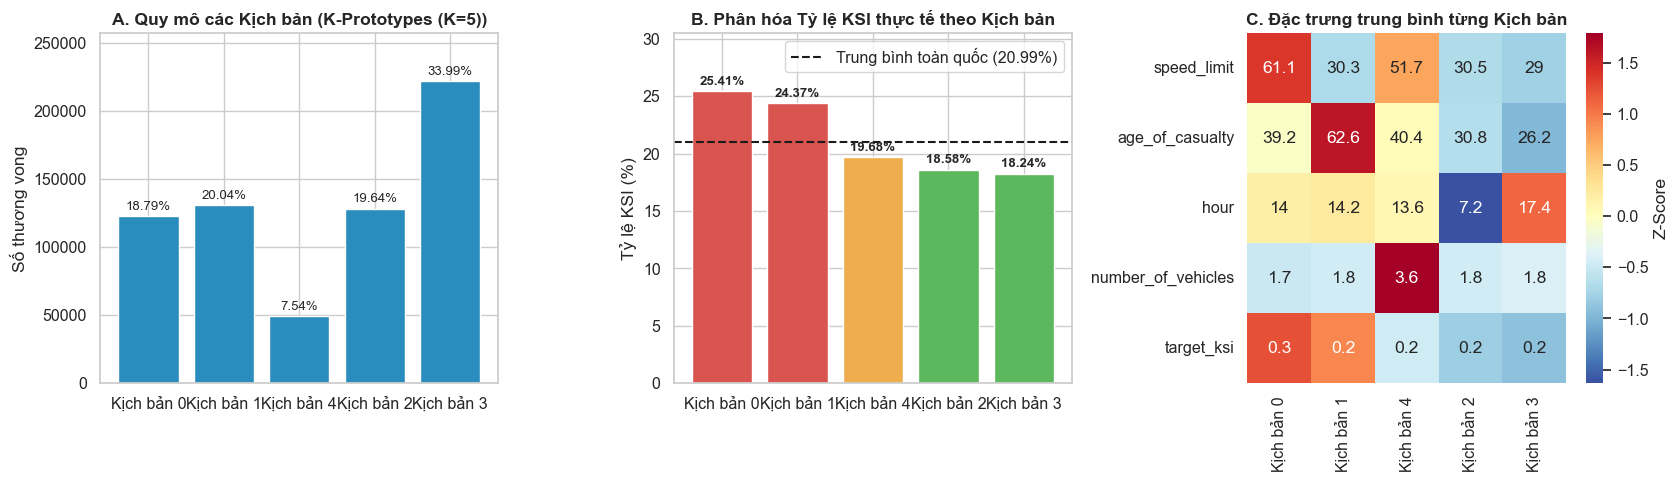


Đã lưu thành công mô hình phân cụm tối ưu tại: D:\OLAP\Data Mining\models\best_clustering_model_bundle.joblib (0.03 MB)


In [8]:
# 1. Gán nhãn cụm kịch bản cho toàn bộ 652.821 bản ghi
df_result = df_work.copy()
df_result["cluster_id"] = full_labels
df_result["target_ksi"] = df["target_ksi"].values
df_result["casualty_severity"] = df["casualty_severity"].values

# 2. Xây dựng Bảng Hồ sơ Chân dung Kịch bản Tai nạn (Cluster Profiles)
profile_rows = []
for cid, grp in df_result.groupby("cluster_id"):
    row = {
        "Cụm (Cluster)": f"Kịch bản {cid}",
        "Số lượng nạn nhân": len(grp),
        "Tỷ trọng (%)": round(len(grp) / len(df_result) * 100, 2),
        "Tỷ lệ KSI thực tế (%)": round(grp["target_ksi"].mean() * 100, 2),
        "Tốc độ TB (mph)": round(grp["speed_limit"].mean(), 1),
        "Tuổi nạn nhân TB": round(grp["age_of_casualty"].mean(), 1),
        "Giờ xảy ra TB": round(grp["hour"].mean(), 1),
        "Số xe TB": round(grp["number_of_vehicles"].mean(), 2),
    }
    for c in cat_cluster_cols:
        top_val = grp[c].mode()[0]
        top_pct = (grp[c] == top_val).mean() * 100
        row[c] = f"{top_val} ({top_pct:.0f}%)"
    profile_rows.append(row)

df_profiles = pd.DataFrame(profile_rows).sort_values(by="Tỷ lệ KSI thực tế (%)", ascending=False)
print(f"=== BẢNG HỒ SƠ CHÂN DUNG CÁC KỊCH BẢN TAI NẠN ({winner_name} — TOÀN BỘ 652.821 BẢN GHI) ===")
display(df_profiles)

# 3. Trực quan hóa 3 biểu đồ tổng hợp chân dung các cụm kịch bản
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Biểu đồ A: Quy mô & Tỷ trọng từng kịch bản
axes[0].bar(df_profiles["Cụm (Cluster)"], df_profiles["Số lượng nạn nhân"], color="#2b8cbe")
axes[0].set_title(f"A. Quy mô các Kịch bản ({winner_name})", fontweight="bold")
axes[0].set_ylabel("Số thương vong")
for i, (_, r) in enumerate(df_profiles.iterrows()):
    axes[0].text(i, r["Số lượng nạn nhân"] + 5000, f"{r['Tỷ trọng (%)']}%", ha="center", fontsize=9.5)
axes[0].set_ylim(0, df_profiles["Số lượng nạn nhân"].max() * 1.16)

# Biểu đồ B: Mức độ rủi ro KSI thực tế theo từng kịch bản (Đối chiếu đường trung bình toàn cục 20.99%)
colors_ksi = ["#d9534f" if v > 23 else ("#f0ad4e" if v >= 19 else "#5cb85c") for v in df_profiles["Tỷ lệ KSI thực tế (%)"]]
axes[1].bar(df_profiles["Cụm (Cluster)"], df_profiles["Tỷ lệ KSI thực tế (%)"], color=colors_ksi)
axes[1].axhline(df_result["target_ksi"].mean() * 100, color="k", linestyle="--", lw=1.5, label="Trung bình toàn quốc (20.99%)")
axes[1].set_title("B. Phân hóa Tỷ lệ KSI thực tế theo Kịch bản", fontweight="bold")
axes[1].set_ylabel("Tỷ lệ KSI (%)")
for i, (_, r) in enumerate(df_profiles.iterrows()):
    axes[1].text(i, r["Tỷ lệ KSI thực tế (%)"] + 0.6, f"{r['Tỷ lệ KSI thực tế (%)']}%", ha="center", fontsize=9.5, fontweight="bold")
axes[1].set_ylim(0, df_profiles["Tỷ lệ KSI thực tế (%)"].max() * 1.2)
axes[1].legend()

# Biểu đồ C: Heatmap đặc trưng số trung bình (Z-score) giữa các cụm
num_means = df_result.groupby("cluster_id")[num_cluster_cols + ["target_ksi"]].mean()
num_means.index = [f"Kịch bản {i}" for i in num_means.index]
num_means = num_means.loc[df_profiles["Cụm (Cluster)"]]
num_z = (num_means - num_means.mean()) / (num_means.std() + 1e-9)

sns.heatmap(num_z.T, annot=num_means.T.round(1), fmt="g", cmap="RdYlBu_r", center=0, ax=axes[2], cbar_kws={"label": "Z-Score"})
axes[2].set_title("C. Đặc trưng trung bình từng Kịch bản", fontweight="bold")

plt.tight_layout()
plt.show()

# 4. Lưu trữ mô hình phân cụm chiến thắng & bảng hồ sơ cụm
clustering_bundle = {
    "winner_name": winner_name,
    "winner_type": winner_type,
    "model": winner_model,
    "num_imputer": num_imputer,
    "scaler": scaler,
    "ord_encoder": ord_encoder,
    "num_cols": num_cluster_cols,
    "cat_cols": cat_cluster_cols,
    "comparison_table": head_to_head.to_dict(orient="records"),
    "cluster_profiles": df_profiles.to_dict(orient="records")
}

CLUSTER_MODEL_FILE = MODEL_DIR / "best_clustering_model_bundle.joblib"
joblib.dump(clustering_bundle, CLUSTER_MODEL_FILE, compress=3)
print(f"\nĐã lưu thành công mô hình phân cụm tối ưu tại: {CLUSTER_MODEL_FILE} ({CLUSTER_MODEL_FILE.stat().st_size / (1024**2):.2f} MB)")